Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

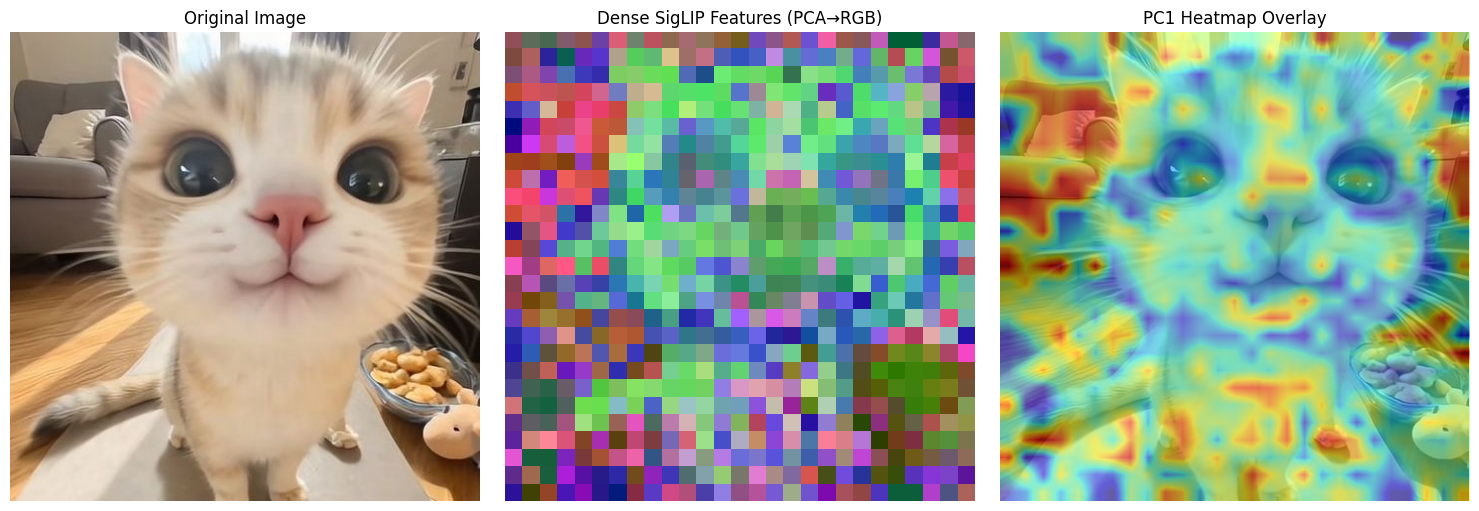

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, AutoProcessor
from PIL import Image

# --- 1. Extract dense features with SigLIP ---
model_name = "google/siglip-so400m-patch14-384"
model = AutoModel.from_pretrained(model_name).eval()
processor = AutoProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    vision_outputs = model.vision_model(**inputs)

last_hidden = vision_outputs.last_hidden_state  # [B, N, D]

# FIX: SigLIP has NO CLS token — all tokens are patch embeddings
patch_tokens = last_hidden  # [1, 729, D] for 27x27 grid

B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)   # 27 (since 27*27 = 729)

patch_tokens_np = patch_tokens[0].numpy()   # [729, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [729, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense SigLIP Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("siglip_dense_features.png", dpi=150)
plt.show()